### Nama : A.Aiman Aziiz Danial
### Nim : H061241003
# Modul: Menyusun Prompt AI yang Baik untuk Permasalahan Geofisika
## Framework R–T–C–I–K–O–Q–V



## 1. Pendahuluan

Dalam pekerjaan geofisika (interpretasi data, inversi, pemodelan), sebuah prompt AI bukan sekadar "pertanyaan singkat" — prompt harus berfungsi sebagai **spesifikasi kerja** (work specification), sama seperti Term of Reference (ToR) dalam proyek nyata. Prompt yang baik membuat keluaran AI dapat diaudit: pembaca bisa menelusuri dasar setiap keputusan yang diambil AI, dan membedakan mana yang benar-benar analisis data dari mana yang sekadar klaim tanpa dasar.

Struktur minimum sebuah prompt dapat digambarkan sebagai alur berikut (mengacu pada Gambar 2.1):


Diagram alur R-T-C-I-K-O-Q-V (Gambar 2.1):


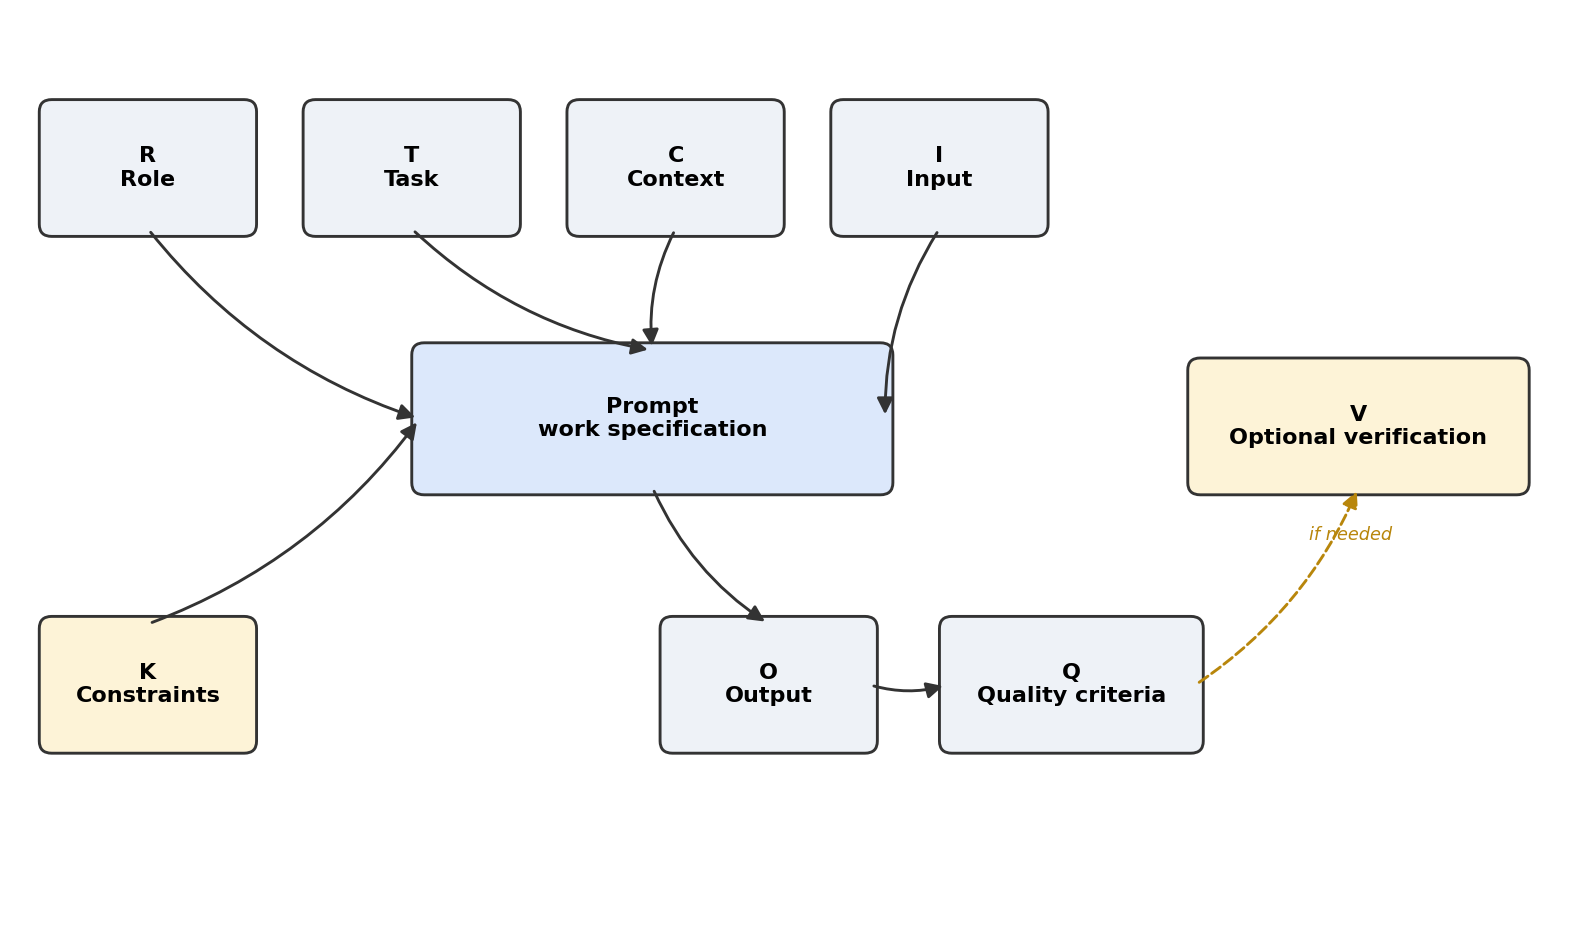

In [2]:
from IPython.display import Image, display
display(Image(filename='diagram.png'))


**R, T, C, I, K** membentuk *spesifikasi pekerjaan* (apa yang dikerjakan dan batasannya), sedangkan **O, Q, (V)** membentuk *deliverable* (apa yang dihasilkan, kriteria penerimaannya, dan verifikasi bila diperlukan).


## 2. Penjelasan Tiap Komponen

| Komponen | Arti | Fungsi dalam Prompt Geofisika |
|---|---|---|
| **R** – Role | Peran yang harus dijalankan AI | Menentukan sudut pandang & level keahlian (mis. "bertindak sebagai geofisikawan eksplorasi") |
| **T** – Task | Tugas spesifik yang harus dikerjakan | Kata kerja aksi yang jelas & terukur (interpretasikan, hitung, bandingkan, buat model) |
| **C** – Context | Latar belakang masalah | Lokasi, metode survei, kondisi geologi, tujuan studi |
| **I** – Input | Data/berkas yang tersedia untuk diproses | Format data, jumlah titik, satuan, sumber data |
| **K** – Constraints | Batasan yang tidak boleh dilanggar | Asumsi yang boleh/tidak boleh dipakai, metode yang wajib dipakai, hal yang dilarang (mis. dilarang mengarang nilai) |
| **O** – Output | Bentuk keluaran yang diminta | Format laporan, jenis grafik, struktur tabel |
| **Q** – Quality criteria | Kriteria agar output diterima | Akurasi, konsistensi satuan, kelengkapan interpretasi |
| **V** – Verification (opsional) | Cara memverifikasi hasil | Uji silang dengan data lapangan/literatur, cek residual, uji sensitivitas |


## 3. Studi Kasus: Interpretasi Data ERT & IP untuk Deteksi Zona Mineralisasi

Berikut contoh penerapan framework di atas untuk kasus nyata geofisika — interpretasi data *Electrical Resistivity Tomography* (ERT) dan *Induced Polarization* (IP) menggunakan bantuan AI, diproses dengan pyGIMLi.


In [3]:
prompt = """
### Role
Anda bertindak sebagai geofisikawan eksplorasi tambang yang berpengalaman
dalam interpretasi data resistivitas dan chargeability (IP), serta memahami
alur kerja inversi geolistrik menggunakan pyGIMLi.

### Task
Interpretasikan hasil inversi 2D data ERT dan IP pada satu lintasan survei,
identifikasi zona anomali yang berpotensi sebagai indikasi mineralisasi
sulfida, dan jelaskan dasar geofisis dari interpretasi tersebut.

### Context
Survei dilakukan pada lintasan sepanjang 200 m dengan spasi elektroda 5 m,
konfigurasi Wenner-Schlumberger, di area yang secara geologi diduga
mengandung endapan sulfida masif. Data telah melalui proses inversi 2D
menggunakan pyGIMLi dengan RMS error di bawah 5%.

### Input
- File hasil inversi resistivitas (.vtk / .txt) berisi nilai resistivitas
  semu dan resistivitas sebenarnya per blok model
- File hasil inversi chargeability (IP) dengan format yang sama
- Informasi kedalaman investigasi maksimum dan RMS error inversi

### Constraints
- Interpretasi hanya boleh didasarkan pada data yang diberikan, tidak boleh
  mengasumsikan data yang tidak tersedia (mis. data litologi bor)
- Nilai resistivitas dan chargeability tidak boleh dimodifikasi atau
  diperkirakan ulang tanpa keterangan eksplisit
- Gunakan satuan standar (Ωm untuk resistivitas, mV/V untuk chargeability)
- Jangan menyimpulkan jenis mineral secara pasti tanpa data pendukung
  (cukup sebutkan sebagai "indikasi" atau "potensi")

### Output
Laporan interpretasi dalam format berikut:
1. Ringkasan kondisi geolistrik lintasan (rentang nilai resistivitas & IP)
2. Identifikasi zona anomali (rendah resistivitas - tinggi chargeability)
   lengkap dengan estimasi posisi (jarak & kedalaman)
3. Interpretasi geologi/mineralisasi yang mungkin, dengan tingkat keyakinan
4. Rekomendasi tindak lanjut (mis. titik bor lanjutan)

### Quality Criteria
- Setiap klaim interpretasi harus merujuk pada nilai numerik dari data input
- Konsisten secara internal (posisi anomali resistivitas & IP yang sama
  harus dirujuk silang)
- Tidak ada informasi yang mengada-ada di luar data yang diberikan

### Optional Verification
Jika tersedia, bandingkan posisi anomali hasil interpretasi dengan data
geologi permukaan atau data bor terdekat untuk menguji konsistensi hasil.
"""
print(prompt)


### Role
Anda bertindak sebagai geofisikawan eksplorasi tambang yang berpengalaman
dalam interpretasi data resistivitas dan chargeability (IP), serta memahami
alur kerja inversi geolistrik menggunakan pyGIMLi.

### Task
Interpretasikan hasil inversi 2D data ERT dan IP pada satu lintasan survei,
identifikasi zona anomali yang berpotensi sebagai indikasi mineralisasi
sulfida, dan jelaskan dasar geofisis dari interpretasi tersebut.

### Context
Survei dilakukan pada lintasan sepanjang 200 m dengan spasi elektroda 5 m,
konfigurasi Wenner-Schlumberger, di area yang secara geologi diduga
mengandung endapan sulfida masif. Data telah melalui proses inversi 2D
menggunakan pyGIMLi dengan RMS error di bawah 5%.

### Input
- File hasil inversi resistivitas (.vtk / .txt) berisi nilai resistivitas
  semu dan resistivitas sebenarnya per blok model
- File hasil inversi chargeability (IP) dengan format yang sama
- Informasi kedalaman investigasi maksimum dan RMS error inversi

### Constraints
- Interp

## 4. Mengapa Prompt di Atas Dianggap Baik

- **Role** membuat AI menjawab dengan level teknis yang sesuai (bukan penjelasan umum untuk awam)
- **Task** menggunakan kata kerja yang jelas dan bisa diukur ("identifikasi", "jelaskan dasar")
- **Context** memberi informasi geologi & teknis survei sehingga interpretasi tidak generik
- **Input** menyebutkan format data secara eksplisit, sehingga AI tahu apa yang bisa dan tidak bisa diolah
- **Constraints** mencegah AI mengarang data atau membuat klaim berlebihan — ini poin penting yang sering diabaikan
- **Output** membuat hasil terstruktur dan mudah dinilai
- **Quality Criteria** menjadi tolok ukur objektif untuk menerima/menolak hasil AI
- **Verification** memberi jalan untuk mengecek validitas hasil bila data pembanding tersedia


## 5. Template Kosong (untuk kasus geofisika lain)


In [4]:
template = """
### Role
[Peran spesifik yang harus dijalankan AI]

### Task
[Tugas dengan kata kerja aksi yang terukur]

### Context
[Latar belakang: lokasi, metode, tujuan studi, kondisi geologi]

### Input
[Data/berkas yang tersedia, format, satuan]

### Constraints
[Batasan, asumsi yang boleh/tidak boleh, larangan mengada-ada]

### Output
[Format keluaran yang diminta]

### Quality Criteria
[Kriteria agar hasil dapat diterima]

### Optional Verification
[Cara memverifikasi hasil, jika relevan]
"""
print(template)


### Role
[Peran spesifik yang harus dijalankan AI]

### Task
[Tugas dengan kata kerja aksi yang terukur]

### Context
[Latar belakang: lokasi, metode, tujuan studi, kondisi geologi]

### Input
[Data/berkas yang tersedia, format, satuan]

### Constraints
[Batasan, asumsi yang boleh/tidak boleh, larangan mengada-ada]

### Output
[Format keluaran yang diminta]

### Quality Criteria
[Kriteria agar hasil dapat diterima]

### Optional Verification
[Cara memverifikasi hasil, jika relevan]



## 6. Catatan Penutup

Framework ini bisa disingkat bila detail sudah tersimpan dalam *configuration* atau *recipe* pendamping (mis. template proyek yang sudah baku), namun kontrak/batasan pekerjaannya tidak boleh hilang — inilah alasan komponen **Constraints** dan **Quality Criteria** tetap wajib ada meski prompt dipersingkat.


In [5]:
from IPython.core.display import HTML

def set_font(font_name):
    display(HTML(f"<style>body {{ font-family: '{font_name}' !important; }}</style>"))

set_font('Times New Roman')  # Menggunakan font Times New Roman